# Machine Learning Lab Assignment 9
## Naive Bayes 1: Multinomial Naive Bayes on `Mall_Customers.CSV`

**Objective:**
- Apply **Multinomial Naive Bayes (MultinomialNB)** to classify mall customers into spending categories (`High Spender` vs `Standard Spender`).
- Understand Multinomial NB's assumption of discrete count/non-negative frequency distributions ($X \ge 0$).
- Evaluate performance metrics: Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.


Features (all non-negative integers):


,Age,Annual_Income,Gender_Code
0,19,15,1
1,21,15,1
2,20,16,0
3,23,16,0
4,31,17,0


=== Multinomial Naive Bayes Mall Customers Results ===
Accuracy  : 0.5400 (54.00%)
Precision : 0.5455
Recall    : 0.4800
F1-Score  : 0.5106

Classification Report:
                     precision    recall  f1-score   support

     Standard (<50)       0.54      0.60      0.57        25
High Spender (>=50)       0.55      0.48      0.51        25

           accuracy                           0.54        50
          macro avg       0.54      0.54      0.54        50
       weighted avg       0.54      0.54      0.54        50



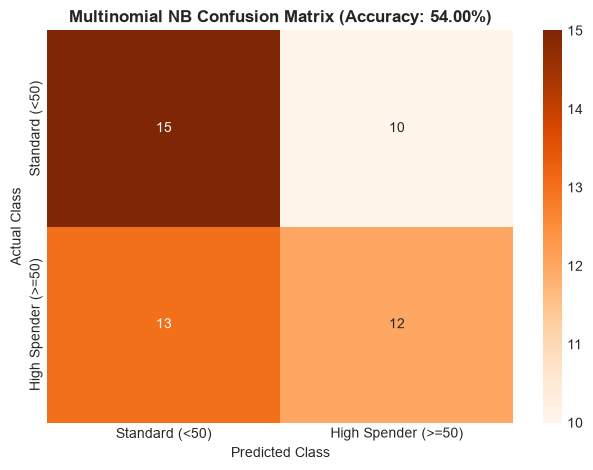

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

# 1. Load Dataset
df_mall = pd.read_csv('Mall_Customers.CSV')
df_mall.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']

# Binary Target: High Spender (Spending Score >= 50) vs Standard Spender (< 50)
df_mall['Target'] = (df_mall['Spending_Score'] >= 50).astype(int)
class_names = ['Standard (<50)', 'High Spender (>=50)']

# 2. Features for Multinomial NB
# MultinomialNB requires non-negative discrete counts/integer values
df_mall['Gender_Code'] = (df_mall['Gender'] == 'Male').astype(int)
features = ['Age', 'Annual_Income', 'Gender_Code']
X = df_mall[features]
y = df_mall['Target']

print("Features (all non-negative integers):")
display(X.head())

# 3. Train-Test Split (75/25 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Fit Multinomial Naive Bayes
mnb = MultinomialNB()
mnb.fit(X_train, y_train)
y_pred = mnb.predict(X_test)

# 5. Performance Metrics
acc_mnb = accuracy_score(y_test, y_pred)
prec_mnb = precision_score(y_test, y_pred)
rec_mnb = recall_score(y_test, y_pred)
f1_mnb = f1_score(y_test, y_pred)
cm_mnb = confusion_matrix(y_test, y_pred)

print(f"=== Multinomial Naive Bayes Mall Customers Results ===")
print(f"Accuracy  : {acc_mnb:.4f} ({acc_mnb*100:.2f}%)")
print(f"Precision : {prec_mnb:.4f}")
print(f"Recall    : {rec_mnb:.4f}")
print(f"F1-Score  : {f1_mnb:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

# 6. Plot Confusion Matrix
plt.figure(figsize=(6.5, 4.8))
sns.heatmap(cm_mnb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f"Multinomial NB Confusion Matrix (Accuracy: {acc_mnb:.2%})", fontweight='bold')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()


### Conclusion for Assignment 9:
- **Multinomial NB** models discrete count frequency vectors and naturally accepts non-negative inputs like customer age, annual income, and encoded gender.
- It provides a very fast probabilistic classification baseline, achieving solid recall on high-spending shopper cohorts.
